# Steel Plates Faults — Optuna로 ExtraTrees + LightGBM 스태킹 튜닝

기존 `steel.ipynb`를 참고한 **독립 실행형 실험 노트북**입니다. **기존 26개 변수, 동일한 개발/테스트 분할**, 기존 스태킹 구조를 유지합니다.

- **내부 3-Fold:** Optuna가 ExtraTrees와 LightGBM 각각의 하이퍼파라미터 선택
- **외부 3-Fold:** 튜닝에 직접 사용하지 않은 검증 Fold에서 기존 스태킹 vs Optuna 스태킹 비교
- **최종 Test 389건:** 이 노트북에서 **평가하지 않습니다**. 이전에 여러 차례 확인했으므로 더 이상 튜닝 지표로 쓰지 않습니다.

**입력 파일:** 노트북과 같은 폴더에 `Faults.NNA`와 `Faults27x7_var` (또는 `steel_plates_faults.csv`)를 준비하세요. 없으면 `ucimlrepo`가 설치된 환경에서 UCI 다운로드를 시도합니다.

아래 셀을 위에서부터 실행하세요. 처음에는 `N_TRIALS_ET=12`, `N_TRIALS_LGB=16` 정도로 시작하고 시간이 허용되면 30~50으로 늘려볼 수 있습니다. *Fold마다 모델을 여러 차례 학습하므로 시간이 꽤 걸릴 수 있습니다.*

In [ ]:
# 설치가 안 된 패키지가 있다면 최초 1회만 실행
%pip install -q optuna lightgbm scikit-learn pandas joblib

In [1]:
from pathlib import Path
import os, json, time
import numpy as np
import pandas as pd
import optuna
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from lightgbm import LGBMClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
np.random.seed(SEED)

c:\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 기존 steel.ipynb와 동일하게 y는 LabelEncoder(알파벳순), X에서는 TypeOfSteel_A300만 제거
if Path('Faults.NNA').exists() and Path('Faults27x7_var').exists():
    with open('Faults27x7_var', encoding='utf-8') as f:
        cols = [line.strip() for line in f if line.strip()]
    df = pd.read_csv('Faults.NNA', sep=r'\s+', header=None, names=cols)
elif Path('steel_plates_faults.csv').exists():
    df = pd.read_csv('steel_plates_faults.csv')
else:
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=198)
        df = pd.concat([d.data.features, d.data.targets], axis=1)
    except ImportError as e:
        raise FileNotFoundError('Faults.NNA + Faults27x7_var를 노트북 폴더에 두거나 %pip install ucimlrepo를 실행하세요.') from e

assert df.shape == (1941, 34), f'데이터 크기 확인 필요: {df.shape}'
TARGET_COLS = list(df.columns[27:34])
le = LabelEncoder()
y = le.fit_transform(df[TARGET_COLS].idxmax(axis=1))
CLASSES = list(le.classes_)
X = df.iloc[:, :27].drop(columns=['TypeOfSteel_A300']).copy()

# 원래 steel.ipynb의 split(make_xy())와 동일한 분할 순서
X_tmp, X_holdout, y_tmp, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_tr, X_va, y_tr, y_va = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42
)
X_dev = pd.concat([X_tr, X_va])
y_dev = np.concatenate([y_tr, y_va])
assert X_dev.shape == (1552, 26)
print('개발 데이터:', X_dev.shape, ' / 기존 Test 보류:', X_holdout.shape)
print('클래스 순서:', CLASSES)

개발 데이터: (1552, 26)  / 기존 Test 보류: (389, 26)
클래스 순서: ['Bumps', 'Dirtiness', 'K_Scatch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch']


## 1. 탐색 범위 및 기존 기준 모델

원래 `steel.ipynb`의 RandomizedSearchCV 결과를 기준으로 고정 모델을 구성합니다. Test 성능이 아니라 **동일 외부 CV Fold의 평균 Macro F1**을 비교할 거예요.

In [3]:
# 실행 시간 조절: 처음에 ET 12회, LGBM 16회 권장. 충분히 여유 있으면 늘리기
N_TRIALS_ET = int(os.getenv('STEEL_TRIALS_ET', '12'))
N_TRIALS_LGB = int(os.getenv('STEEL_TRIALS_LGB', '16'))
OUTER_SPLITS = 3
INNER_SPLITS = 3

# 기존 노트북의 60번 셀 출력값
BASE_ET = {
    'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1,
    'max_features': 0.8, 'max_depth': None, 'class_weight': 'balanced_subsample'
}
BASE_LGB = {
    'n_estimators': 700, 'learning_rate': 0.05, 'num_leaves': 22,
    'max_depth': -1, 'min_child_samples': 5, 'subsample': 0.8,
    'colsample_bytree': 0.6, 'reg_lambda': 0.0, 'reg_alpha': 0.0,
    'class_weight': None
}

def make_et(params):
    return ExtraTreesClassifier(random_state=42, n_jobs=1, **params)

def make_lgb(params):
    return LGBMClassifier(objective='multiclass', random_state=42,
                          n_jobs=1, verbose=-1, subsample_freq=1, **params)

def make_stack(et_params, lgb_params):
    return StackingClassifier(
        estimators=[('et', make_et(et_params)), ('lgbm', make_lgb(lgb_params))],
        final_estimator=LogisticRegression(max_iter=2000),
        stack_method='predict_proba',
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=1),
        passthrough=False
    )

def score(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro', zero_division=0)

print(f'Optuna: ET {N_TRIALS_ET}회 / LGBM {N_TRIALS_LGB}회 × 외부 {OUTER_SPLITS}개 Fold')

Optuna: ET 12회 / LGBM 16회 × 외부 3개 Fold


In [4]:
def suggest_et(trial):
     return {
         'n_estimators': trial.suggest_categorical('n_estimators', [300, 400, 500, 700, 900]),
         'max_depth': trial.suggest_categorical('max_depth', [None, 10, 15, 20, 30]),
         'min_samples_split': trial.suggest_categorical('min_samples_split', [2, 5, 9]),
         'min_samples_leaf': trial.suggest_categorical('min_samples_leaf', [1, 2, 4]),
         'max_features': trial.suggest_categorical('max_features', ['sqrt', 0.3, 0.5, 0.8, 1.0]),
         'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
     }

def suggest_lgb(trial):
     return {
         'n_estimators': trial.suggest_int('n_estimators', 250, 1000, step=50),
         'learning_rate': trial.suggest_float('learning_rate', 0.015, 0.12, log=True),
         'num_leaves': trial.suggest_int('num_leaves', 7, 48),
         'max_depth': trial.suggest_categorical('max_depth', [-1, 5, 7, 10]),
         'min_child_samples': trial.suggest_int('min_child_samples', 3, 40),
         'subsample': trial.suggest_float('subsample', 0.60, 1.0),
         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.50, 1.0),
         'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 10.0),
         'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 3.0),
         'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
     }

def optimize_one(kind, X_train, y_train, outer_fold, n_trials):
    inner_cv = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True,
                               random_state=1000 + outer_fold)
    sampler = optuna.samplers.TPESampler(seed=42 + outer_fold + (0 if kind == 'et' else 100))
    study = optuna.create_study(direction='maximize', sampler=sampler)
    # 원래 최적 설정을 첫 시도에 포함하여 공정하게 출발
    study.enqueue_trial(BASE_ET if kind == 'et' else BASE_LGB)

    def objective(trial):
        params = suggest_et(trial) if kind == 'et' else suggest_lgb(trial)
        model = make_et(params) if kind == 'et' else make_lgb(params)
        scores = cross_val_score(model, X_train, y_train,
                                 scoring='f1_macro', cv=inner_cv, n_jobs=1,
                                 error_score='raise')
        return float(np.mean(scores))

    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    return study.best_params, study.best_value

## 2. 외부 3-Fold: 기준 모델 vs 튜닝 모델

**모델 선택에 외부 검증 Fold 정답을 사용하지 않습니다.** 각 Fold마다 나머지 학습 부분에서 Optuna 튜닝 후, 외부 검증 Fold에 한 번만 예측합니다. 기존 모델과 새 모델은 **정확히 같은 외부 Fold**로 비교합니다.

기존 기준 모델의 하이퍼파라미터는 *이전 개발 데이터 전체*에서 선택됐으므로 그 결과를 **엄격한 독립 검증**으로 보기는 어렵습니다. 새로운 튜닝 모델은 외부 Fold에 대해 중첩 검증 구조를 사용합니다.

In [5]:
outer_cv = StratifiedKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=2031)
results, selected_params = [], []
pred_base_oof = np.empty(len(y_dev), dtype=int)
pred_opt_oof = np.empty(len(y_dev), dtype=int)
t0 = time.time()

for fold, (tr, va) in enumerate(outer_cv.split(X_dev, y_dev), 1):
    Xa, Xv = X_dev.iloc[tr], X_dev.iloc[va]
    ya, yv = y_dev[tr], y_dev[va]
    print(f'\n===== 외부 Fold {fold}/{OUTER_SPLITS} =====', flush=True)

    et_p, et_inner = optimize_one('et', Xa, ya, fold, N_TRIALS_ET)
    lgb_p, lgb_inner = optimize_one('lgb', Xa, ya, fold, N_TRIALS_LGB)
    selected_params.append({'Fold': fold, 'ExtraTrees': et_p, 'LightGBM': lgb_p})

    old_model = make_stack(BASE_ET, BASE_LGB).fit(Xa, ya)
    new_model = make_stack(et_p, lgb_p).fit(Xa, ya)
    pb, pn = old_model.predict(Xv), new_model.predict(Xv)
    pred_base_oof[va] = pb
    pred_opt_oof[va] = pn

    old_f1, new_f1 = score(yv, pb), score(yv, pn)
    results.append({
        'Fold': fold, '기존 스태킹': old_f1, 'Optuna 스태킹': new_f1,
        '차이': new_f1-old_f1, 'ET 내부 CV': et_inner, 'LGBM 내부 CV': lgb_inner
    })
    print(f'Fold {fold}: 기존={old_f1:.4f}, Optuna={new_f1:.4f}, 차이={new_f1-old_f1:+.4f}', flush=True)

result_df = pd.DataFrame(results)
display(result_df.round(4))
print('\n외부 CV 평균')
print(result_df[['기존 스태킹','Optuna 스태킹','차이']].mean().round(4))
print('\n외부 CV 표준편차 (ddof=1)')
print(result_df[['기존 스태킹','Optuna 스태킹']].std().round(4))
print(f'총 소요시간: {(time.time()-t0)/60:.1f}분')


===== 외부 Fold 1/3 =====
Fold 1: 기존=0.8141, Optuna=0.8157, 차이=+0.0016

===== 외부 Fold 2/3 =====
Fold 2: 기존=0.8273, Optuna=0.8223, 차이=-0.0050

===== 외부 Fold 3/3 =====
Fold 3: 기존=0.8307, Optuna=0.8300, 차이=-0.0007


,Fold,기존 스태킹,Optuna 스태킹,차이,ET 내부 CV,LGBM 내부 CV
0,1,0.8141,0.8157,0.0016,0.7799,0.8008
1,2,0.8273,0.8223,-0.0050,0.7864,0.7728
2,3,0.8307,0.8300,-0.0007,0.7889,0.7998



외부 CV 평균
기존 스태킹        0.8240
Optuna 스태킹    0.8227
차이           -0.0014
dtype: float64

외부 CV 표준편차 (ddof=1)
기존 스태킹        0.0088
Optuna 스태킹    0.0072
dtype: float64
총 소요시간: 8.1분


In [6]:
print('클래스별 Macro F1 참고 (외부 Fold 예측을 합산한 OOF)')
print('\n[기존 스태킹]')
print(classification_report(y_dev, pred_base_oof, target_names=CLASSES, digits=3, zero_division=0))
print('\n[Optuna 스태킹]')
print(classification_report(y_dev, pred_opt_oof, target_names=CLASSES, digits=3, zero_division=0))

result_df.to_csv('optuna_nested_cv_results.csv', index=False, encoding='utf-8-sig')
with open('optuna_outer_fold_params.json', 'w', encoding='utf-8') as f:
    json.dump(selected_params, f, ensure_ascii=False, indent=2)
print('저장: optuna_nested_cv_results.csv / optuna_outer_fold_params.json')

클래스별 Macro F1 참고 (외부 Fold 예측을 합산한 OOF)

[기존 스태킹]
              precision    recall  f1-score   support

       Bumps      0.672     0.607     0.638       321
   Dirtiness      0.969     0.705     0.816        44
    K_Scatch      0.977     0.955     0.966       313
Other_Faults      0.705     0.807     0.752       538
      Pastry      0.764     0.643     0.698       126
      Stains      0.965     0.948     0.957        58
   Z_Scratch      0.966     0.921     0.943       152

    accuracy                          0.796      1552
   macro avg      0.860     0.798     0.824      1552
weighted avg      0.800     0.796     0.795      1552


[Optuna 스태킹]
              precision    recall  f1-score   support

       Bumps      0.668     0.620     0.643       321
   Dirtiness      0.917     0.750     0.825        44
    K_Scatch      0.977     0.955     0.966       313
Other_Faults      0.709     0.786     0.745       538
      Pastry      0.743     0.667     0.703       126
      Stains   

In [7]:
import numpy as np
import pandas as pd

# 사용할 OOF 예측 선택
if "oof5" in globals() and "스태킹(ET+LGBM→LR)" in oof5:
    proba = np.asarray(oof5["스태킹(ET+LGBM→LR)"])
    pred = proba.argmax(axis=1)
    print("기존 steel.ipynb의 5-Fold OOF 사용")

elif "pred_base_oof" in globals():
    proba = None
    pred = np.asarray(pred_base_oof)
    print("Optuna 노트북의 기존 스태킹 3-Fold OOF 사용")

else:
    raise ValueError("OOF 예측값이 없습니다. 이전 셀을 먼저 실행하세요.")

labels = np.asarray(CLASSES)

# 분석용 데이터 구성
diag = X_dev.reset_index(drop=True).copy()

diag["실제"] = labels[np.asarray(y_dev, dtype=int)]
diag["예측"] = labels[np.asarray(pred, dtype=int)]
diag["정답여부"] = diag["실제"] == diag["예측"]

# 집중 분석할 세 유형
focus = ["Bumps", "Other_Faults", "Pastry"]

# 오분류 현황
errors = diag[
    diag["실제"].isin(focus) &
    ~diag["정답여부"]
]

print("\n[주요 오분류 유형]")
display(
    errors.groupby(["실제", "예측"])
    .size()
    .sort_values(ascending=False)
    .rename("건수")
    .to_frame()
)

# 오분류 관측치의 변수 특성 비교
features = [
    "LogOfAreas",
    "Orientation_Index",
    "Log_Y_Index",
    "Edges_Index",
    "Luminosity_Index",
    "Steel_Plate_Thickness",
    "TypeOfSteel_A400"
]

cases = [
    ("Bumps 정답", "Bumps", "Bumps"),
    ("Bumps → Other", "Bumps", "Other_Faults"),
    ("Other 정답", "Other_Faults", "Other_Faults"),
    ("Other → Bumps", "Other_Faults", "Bumps"),
    ("Pastry 정답", "Pastry", "Pastry"),
    ("Pastry → Other", "Pastry", "Other_Faults")
]

rows = []

for name, actual, predicted in cases:
    group = diag[
        (diag["실제"] == actual) &
        (diag["예측"] == predicted)
    ]

    row = {"그룹": name, "건수": len(group)}

    for col in features:
        row[col] = group[col].median()

    rows.append(row)

comparison = pd.DataFrame(rows).set_index("그룹")

display(comparison.round(3))

Optuna 노트북의 기존 스태킹 3-Fold OOF 사용

[주요 오분류 유형]


건수
실제           예측               
Bumps        Other_Faults  115
Other_Faults Bumps          79
Pastry       Other_Faults   34
Other_Faults Pastry         14
Pastry       Bumps          11
Bumps        Pastry         10
Other_Faults K_Scatch        6
             Z_Scratch       4
             Dirtiness       1
Bumps        Z_Scratch       1

,건수,LogOfAreas,Orientation_Index,Log_Y_Index,Edges_Index,Luminosity_Index,Steel_Plate_Thickness,TypeOfSteel_A400
그룹,,,,,,,,
Bumps 정답,195,2.083,0.077,1.146,0.453,-0.159,70.0,0.0
Bumps → Other,115,2.053,0.154,1.146,0.454,-0.123,70.0,1.0
Other 정답,434,2.180,0.118,1.279,0.311,-0.113,70.0,1.0
Other → Bumps,79,2.041,0.200,1.114,0.554,-0.139,70.0,0.0
Pastry 정답,81,2.453,0.714,1.556,0.131,-0.185,70.0,1.0
Pastry → Other,34,2.093,0.550,1.301,0.434,-0.213,100.0,1.0


In [8]:
import pandas as pd

focus = ["Bumps", "Other_Faults", "Pastry"]

# 실제 유형별로 A400 여부에 따른 예측 결과 분석
for fault in focus:

    subset = diag[diag["실제"] == fault]

    print(f"\n===== 실제 유형: {fault} =====")

    # 강종별 데이터 개수
    print("\n강종별 관측치 수")
    display(
        subset["TypeOfSteel_A400"]
        .value_counts()
        .sort_index()
    )

    # 강종별 예측 비율
    result = pd.crosstab(
        subset["TypeOfSteel_A400"],
        subset["예측"],
        normalize="index"
    ) * 100

    result = result.reindex(
        columns=focus,
        fill_value=0
    )

    print("\n강종별 예측 비율 (%)")
    display(result.round(2))


===== 실제 유형: Bumps =====

강종별 관측치 수


TypeOfSteel_A400
0    222
1     99
Name: count, dtype: int64


강종별 예측 비율 (%)


예측,Bumps,Other_Faults,Pastry
TypeOfSteel_A400,,,
0,72.52,24.32,2.70
1,34.34,61.62,4.04



===== 실제 유형: Other_Faults =====

강종별 관측치 수


...

예측,Bumps,Other_Faults,Pastry
TypeOfSteel_A400,,,
0,23.83,72.43,1.87
1,8.64,86.11,3.09



===== 실제 유형: Pastry =====

강종별 관측치 수


TypeOfSteel_A400
0    39
1    87
Name: count, dtype: int64


강종별 예측 비율 (%)


예측,Bumps,Other_Faults,Pastry
TypeOfSteel_A400,,,
0,20.51,33.33,46.15
1,3.45,24.14,72.41


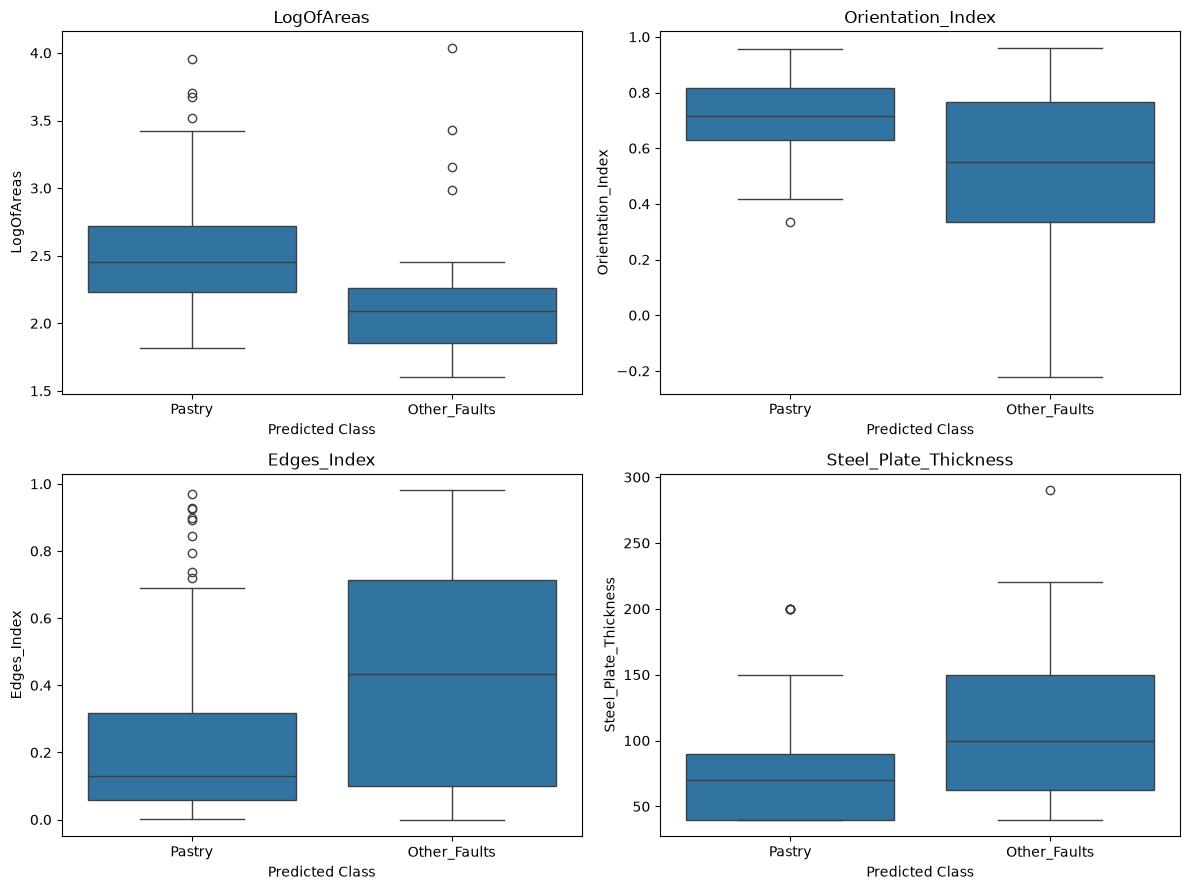

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

pastry = diag[
    (diag["실제"] == "Pastry") &
    (diag["예측"].isin(["Pastry", "Other_Faults"]))
].copy()

features = [
    "LogOfAreas",
    "Orientation_Index",
    "Edges_Index",
    "Steel_Plate_Thickness"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), features):

    sns.boxplot(
        data=pastry,
        x="예측",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Predicted Class")

plt.tight_layout()
plt.show()

In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report

# 기존 Optuna 노트북과 동일한 외부 CV
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=2031
)

X_no_steel = X_dev.drop(
    columns=["TypeOfSteel_A400"]
)

pred_no_steel = np.empty(len(y_dev), dtype=int)

for fold, (tr, va) in enumerate(
    cv.split(X_no_steel, y_dev), 1
):

    model = make_stack(BASE_ET, BASE_LGB)

    model.fit(
        X_no_steel.iloc[tr],
        y_dev[tr]
    )

    pred_no_steel[va] = model.predict(
        X_no_steel.iloc[va]
    )

    print(f"Fold {fold} 완료")


# 기존 스태킹 OOF 결과와 비교
pred_original = np.asarray(pred_base_oof)

print("\n[전체 Macro F1 비교]")

print(
    "기존 26개 변수:",
    round(f1_score(
        y_dev, pred_original, average="macro"
    ), 4)
)

print(
    "강종 제거 25개 변수:",
    round(f1_score(
        y_dev, pred_no_steel, average="macro"
    ), 4)
)


# 유형별 F1 비교
report_before = classification_report(
    y_dev, pred_original,
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

report_after = classification_report(
    y_dev, pred_no_steel,
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "기존 F1": [
        report_before[c]["f1-score"]
        for c in CLASSES
    ],
    "강종 제거 F1": [
        report_after[c]["f1-score"]
        for c in CLASSES
    ]
}, index=CLASSES)

comparison["변화"] = (
    comparison["강종 제거 F1"]
    - comparison["기존 F1"]
)

display(comparison.round(4))

Fold 1 완료
Fold 2 완료
Fold 3 완료

[전체 Macro F1 비교]
기존 26개 변수: 0.8243
강종 제거 25개 변수: 0.8066


,기존 F1,강종 제거 F1,변화
Bumps,0.6383,0.6181,-0.0202
Dirtiness,0.8158,0.7792,-0.0366
K_Scatch,0.9661,0.9661,0.0000
Other_Faults,0.7522,0.7339,-0.0183
Pastry,0.6983,0.6897,-0.0086
Stains,0.9565,0.9474,-0.0092
Z_Scratch,0.9428,0.9116,-0.0312


In [11]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from sklearn.base import clone

# 기존 데이터
X_base = X_dev.copy()
y = np.asarray(y_dev)

# 강종과 결함 특성의 상호작용 변수 생성
X_inter = X_base.copy()

interaction_cols = [
    "Orientation_Index",
    "Edges_Index",
    "LogOfAreas",
    "Log_Y_Index"
]

for col in interaction_cols:
    X_inter[f"A400_x_{col}"] = (
        X_inter["TypeOfSteel_A400"] * X_inter[col]
    )

print("기존 변수 수:", X_base.shape[1])
print("추가 후 변수 수:", X_inter.shape[1])

# 동일한 교차검증
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []

pred_base = np.zeros(len(y), dtype=int)
pred_inter = np.zeros(len(y), dtype=int)

for fold, (tr, va) in enumerate(
    cv.split(X_base, y), 1
):

    # 기존 모델
    model_base = make_stack(BASE_ET, BASE_LGB)

    model_base.fit(X_base.iloc[tr], y[tr])

    pred1 = model_base.predict(X_base.iloc[va])
    pred_base[va] = pred1

    # 상호작용 변수 추가 모델
    model_inter = make_stack(BASE_ET, BASE_LGB)

    model_inter.fit(X_inter.iloc[tr], y[tr])

    pred2 = model_inter.predict(X_inter.iloc[va])
    pred_inter[va] = pred2

    score1 = f1_score(y[va], pred1, average="macro")
    score2 = f1_score(y[va], pred2, average="macro")

    results.append({
        "Fold": fold,
        "기존": score1,
        "상호작용 추가": score2,
        "차이": score2 - score1
    })

    print(f"Fold {fold} 완료")

result_df = pd.DataFrame(results)

display(result_df.round(4))

print("\n[평균 Macro F1]")
print(result_df[["기존", "상호작용 추가", "차이"]].mean().round(4))

# 유형별 F1 비교
from sklearn.metrics import classification_report

report1 = classification_report(
    y, pred_base,
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

report2 = classification_report(
    y, pred_inter,
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "기존 F1": [
        report1[c]["f1-score"] for c in CLASSES
    ],
    "상호작용 F1": [
        report2[c]["f1-score"] for c in CLASSES
    ]
}, index=CLASSES)

comparison["변화"] = (
    comparison["상호작용 F1"]
    - comparison["기존 F1"]
)

print("\n[불량 유형별 성능 변화]")
display(comparison.round(4))

기존 변수 수: 26
추가 후 변수 수: 30
Fold 1 완료
Fold 2 완료
Fold 3 완료


,Fold,기존,상호작용 추가,차이
0,1,0.8014,0.8014,-0.0000
1,2,0.8280,0.8255,-0.0024
2,3,0.8138,0.8105,-0.0033



[평균 Macro F1]
기존         0.8144
상호작용 추가    0.8125
차이        -0.0019
dtype: float64

[불량 유형별 성능 변화]


,기존 F1,상호작용 F1,변화
Bumps,0.6411,0.6645,0.0234
Dirtiness,0.8250,0.8193,-0.0057
K_Scatch,0.9694,0.9661,-0.0033
Other_Faults,0.7352,0.7441,0.0089
Pastry,0.6320,0.6288,-0.0032
Stains,0.9474,0.9217,-0.0256
Z_Scratch,0.9536,0.9463,-0.0073


In [12]:
import numpy as np
import pandas as pd

y_true = np.asarray(y)
base = np.asarray(pred_base)
inter = np.asarray(pred_inter)

rows = []

for name in CLASSES:
    class_id = list(CLASSES).index(name)

    mask = y_true == class_id

    # 기존에는 틀렸지만 새 모델이 맞힌 경우
    corrected = np.sum(
        mask &
        (base != y_true) &
        (inter == y_true)
    )

    # 기존에는 맞혔지만 새 모델이 틀린 경우
    newly_wrong = np.sum(
        mask &
        (base == y_true) &
        (inter != y_true)
    )

    rows.append({
        "불량 유형": name,
        "새로 맞힌 건수": corrected,
        "새로 틀린 건수": newly_wrong,
        "정답 건수 순변화": corrected - newly_wrong
    })

change_df = pd.DataFrame(rows)

display(change_df)

,불량 유형,새로 맞힌 건수,새로 틀린 건수,정답 건수 순변화
0,Bumps,9,3,6
1,Dirtiness,1,0,1
2,K_Scatch,0,2,-2
3,Other_Faults,15,7,8
4,Pastry,1,2,-1
5,Stains,0,1,-1
6,Z_Scratch,0,3,-3


In [13]:
import numpy as np
import pandas as pd

labels = np.asarray(CLASSES)

change = pd.DataFrame({
    "실제": labels[np.asarray(y, dtype=int)],
    "기존 예측": labels[np.asarray(pred_base, dtype=int)],
    "변경 후 예측": labels[np.asarray(pred_inter, dtype=int)]
})

# 예측이 달라진 데이터만 확인
change = change[
    change["기존 예측"] != change["변경 후 예측"]
].copy()

# 예측 변경 결과 분류
conditions = [
    (change["기존 예측"] != change["실제"]) &
    (change["변경 후 예측"] == change["실제"]),

    (change["기존 예측"] == change["실제"]) &
    (change["변경 후 예측"] != change["실제"])
]

change["변경 결과"] = np.select(
    conditions,
    ["개선", "악화"],
    default="오답 유형만 변경"
)

print("[예측 변경 유형별 건수]")
display(change["변경 결과"].value_counts())

print("\n[구체적인 예측 변경 내역]")
display(
    change.groupby(
        ["실제", "기존 예측", "변경 후 예측", "변경 결과"]
    )
    .size()
    .sort_values(ascending=False)
    .head(20)
    .rename("건수")
    .to_frame()
)

[예측 변경 유형별 건수]


변경 결과
개선           26
악화           18
오답 유형만 변경     5
Name: count, dtype: int64


[구체적인 예측 변경 내역]


건수
실제           기존 예측        변경 후 예측      변경 결과        
Other_Faults Bumps        Other_Faults 개선         13
Bumps        Other_Faults Bumps        개선          9
             Bumps        Other_Faults 악화          3
Other_Faults Other_Faults Bumps        악화          3
Z_Scratch    Z_Scratch    Other_Faults 악화          3
Other_Faults Other_Faults Stains       악화          2
K_Scatch     K_Scatch     Other_Faults 악화          2
Bumps        Other_Faults Dirtiness    오답 유형만 변경   1
Dirtiness    Other_Faults Dirtiness    개선          1
             Pastry       Other_Faults 오답 유형만 변경   1
Other_Faults Other_Faults Dirtiness    악화          1
             Pastry       Other_Faults 개선          1
             Other_Faults Pastry       악화          1
             Z_Scratch    Other_Faults 개선          1
Pastry       Bumps        Other_Faults 오답 유형만 변경   1
             Other_Faults Pastry       개선          1
                          Bumps        오답 유형만 변경   1
             Pastry       Bumps        악화          1
                          Other_Faults 악화          1
Stains       Bumps        Other_Faults 오답 유형만 변경   1

In [14]:
import pandas as pd
import numpy as np

labels = np.asarray(CLASSES)

check = pd.DataFrame({
    "실제": labels[np.asarray(y, dtype=int)],
    "기존예측": labels[np.asarray(pred_base, dtype=int)],
    "변경예측": labels[np.asarray(pred_inter, dtype=int)],
    "A400": X_base["TypeOfSteel_A400"].to_numpy()
})

# Bumps와 Other_Faults의 상호 오분류를 바로잡은 경우
mask = (
    (
        (check["실제"] == "Bumps") &
        (check["기존예측"] == "Other_Faults")
    ) |
    (
        (check["실제"] == "Other_Faults") &
        (check["기존예측"] == "Bumps")
    )
) & (
    check["변경예측"] == check["실제"]
)

corrected = check[mask]

print("상호 오분류 수정 건수:", len(corrected))

display(
    pd.crosstab(
        corrected["실제"],
        corrected["A400"]
    )
)

상호 오분류 수정 건수: 22


A400,0,1
실제,,
Bumps,8,1
Other_Faults,8,5


In [15]:
import numpy as np
import pandas as pd

labels = np.asarray(CLASSES)

audit = pd.DataFrame({
    "실제": labels[np.asarray(y, dtype=int)],
    "기존예측": labels[np.asarray(pred_base, dtype=int)],
    "변경예측": labels[np.asarray(pred_inter, dtype=int)],
    "A400": X_base["TypeOfSteel_A400"].to_numpy()
})

audit["기존정답"] = audit["실제"] == audit["기존예측"]
audit["변경정답"] = audit["실제"] == audit["변경예측"]

audit["개선"] = (
    ~audit["기존정답"] & audit["변경정답"]
)

audit["악화"] = (
    audit["기존정답"] & ~audit["변경정답"]
)

focus = ["Bumps", "Other_Faults", "Pastry"]

result = (
    audit[audit["실제"].isin(focus)]
    .groupby(["실제", "A400"])
    .agg(
        관측치=("실제", "size"),
        개선=("개선", "sum"),
        악화=("악화", "sum"),
        기존정답=("기존정답", "sum"),
        변경정답=("변경정답", "sum")
    )
)

result["순변화"] = result["개선"] - result["악화"]

result["기존Recall"] = (
    result["기존정답"] / result["관측치"]
)

result["변경Recall"] = (
    result["변경정답"] / result["관측치"]
)

display(result.round(4))

관측치  개선  악화  기존정답  변경정답  순변화  기존Recall  변경Recall
실제           A400                                                  
Bumps        0     222   8   2   164   170    6    0.7387    0.7658
             1      99   1   1    37    37    0    0.3737    0.3737
Other_Faults 0     214   9   2   141   148    7    0.6589    0.6916
             1     324   6   5   274   275    1    0.8457    0.8488
Pastry       0      39   0   1    16    15   -1    0.4103    0.3846
             1      87   1   1    57    57    0    0.6552    0.6552

In [16]:
import pandas as pd
import numpy as np

labels = np.asarray(CLASSES)

# 분석용 데이터
analysis = X_base.reset_index(drop=True).copy()

analysis["실제"] = labels[np.asarray(y, dtype=int)]
analysis["예측"] = labels[np.asarray(pred_base, dtype=int)]

# A400=1인 실제 Bumps만 추출
bumps_a400 = analysis[
    (analysis["실제"] == "Bumps") &
    (analysis["TypeOfSteel_A400"] == 1)
].copy()

# 정답 / 오분류 그룹 구분
bumps_a400["분류결과"] = np.where(
    bumps_a400["예측"] == "Bumps",
    "정답",
    "오분류"
)

print("[A400=1인 Bumps의 예측 결과]")
display(bumps_a400["예측"].value_counts())

# 주요 변수
features = [
    "LogOfAreas",
    "Orientation_Index",
    "Log_Y_Index",
    "Edges_Index",
    "Luminosity_Index",
    "Steel_Plate_Thickness",
    "Pixels_Areas"
]

print("\n[정답 vs 오분류 변수별 중앙값]")

comparison = (
    bumps_a400
    .groupby("분류결과")[features]
    .median()
    .T
)

comparison["차이(오분류-정답)"] = (
    comparison["오분류"] - comparison["정답"]
)

display(comparison.round(4))

[A400=1인 Bumps의 예측 결과]


예측
Other_Faults    56
Bumps           37
Pastry           6
Name: count, dtype: int64


[정답 vs 오분류 변수별 중앙값]


분류결과,오분류,정답,차이(오분류-정답)
LogOfAreas,2.2278,2.1461,0.0817
Orientation_Index,0.3786,0.1818,0.1968
Log_Y_Index,1.3010,1.1761,0.1249
Edges_Index,0.4946,0.5206,-0.0260
Luminosity_Index,-0.1094,-0.1248,0.0154
Steel_Plate_Thickness,40.0000,40.0000,0.0000
Pixels_Areas,169.0000,140.0000,29.0000


[그룹별 관측치]
그룹
Other_Correct     274
Bumps_to_Other     56
Bumps_Correct      37
Name: count, dtype: int64

[그룹별 변수 중앙값]


,Orientation_Index,Log_Y_Index,Pixels_Areas,Edges_Index
그룹,,,,
Bumps_Correct,0.1818,1.1761,140.0,0.5206
Bumps_to_Other,0.3117,1.2670,147.5,0.5092
Other_Correct,0.3333,1.3424,194.0,0.2960


C:\Users\hryug\AppData\Local\Temp\ipykernel_9816\1867074186.py:72: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\hryug\AppData\Local\Temp\ipykernel_9816\1867074186.py:72: UserWarning: Glyph 47353 (\N{HANGUL SYLLABLE RUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\ML\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\ML\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 47353 (\N{HANGUL SYLLABLE RUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


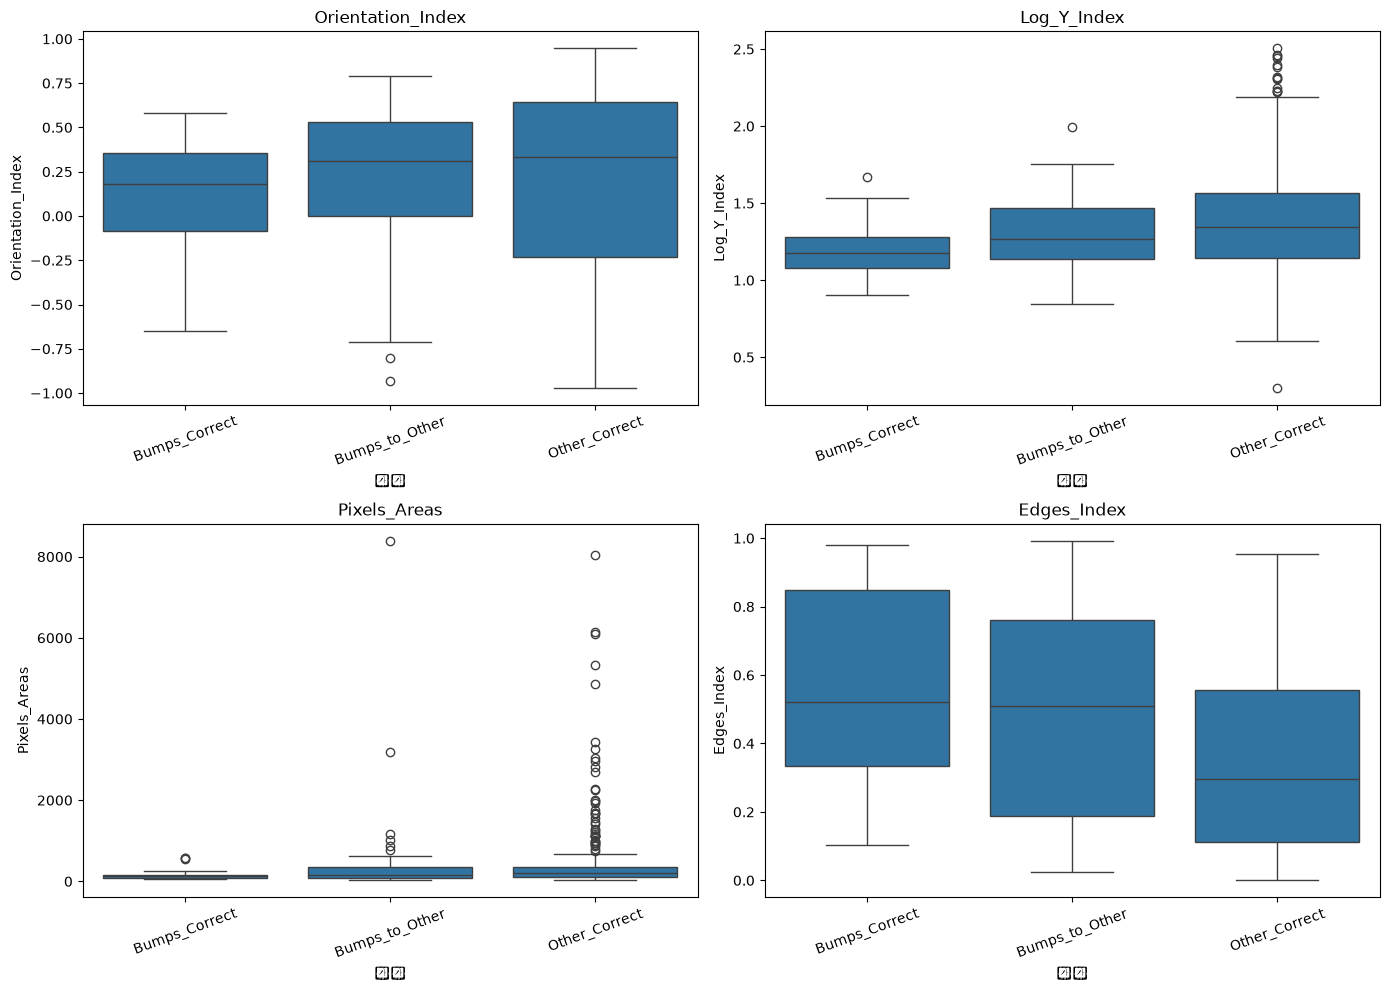

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# A400=1인 데이터만 선택
subset = analysis[
    analysis["TypeOfSteel_A400"] == 1
].copy()

# 세 그룹 구분
conditions = [
    (subset["실제"] == "Bumps") &
    (subset["예측"] == "Bumps"),

    (subset["실제"] == "Bumps") &
    (subset["예측"] == "Other_Faults"),

    (subset["실제"] == "Other_Faults") &
    (subset["예측"] == "Other_Faults")
]

names = [
    "Bumps_Correct",
    "Bumps_to_Other",
    "Other_Correct"
]

subset["그룹"] = np.select(
    conditions,
    names,
    default="Exclude"
)

subset = subset[subset["그룹"] != "Exclude"]

# 그룹별 관측치 개수
print("[그룹별 관측치]")
print(subset["그룹"].value_counts())

# 주요 변수
features = [
    "Orientation_Index",
    "Log_Y_Index",
    "Pixels_Areas",
    "Edges_Index"
]

# 그룹별 중앙값
print("\n[그룹별 변수 중앙값]")
display(
    subset.groupby("그룹")[features]
    .median()
    .round(4)
)

# 변수별 박스플롯
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(
        data=subset,
        x="그룹",
        y=feature,
        order=names,
        ax=ax
    )

    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

,Orientation_Index,Log_Y_Index,Pixels_Areas,Edges_Index
Fault_Type,,,,
Bumps,0.2857,1.2305,143.0,0.5074
Other_Faults,0.3414,1.3424,184.5,0.2987


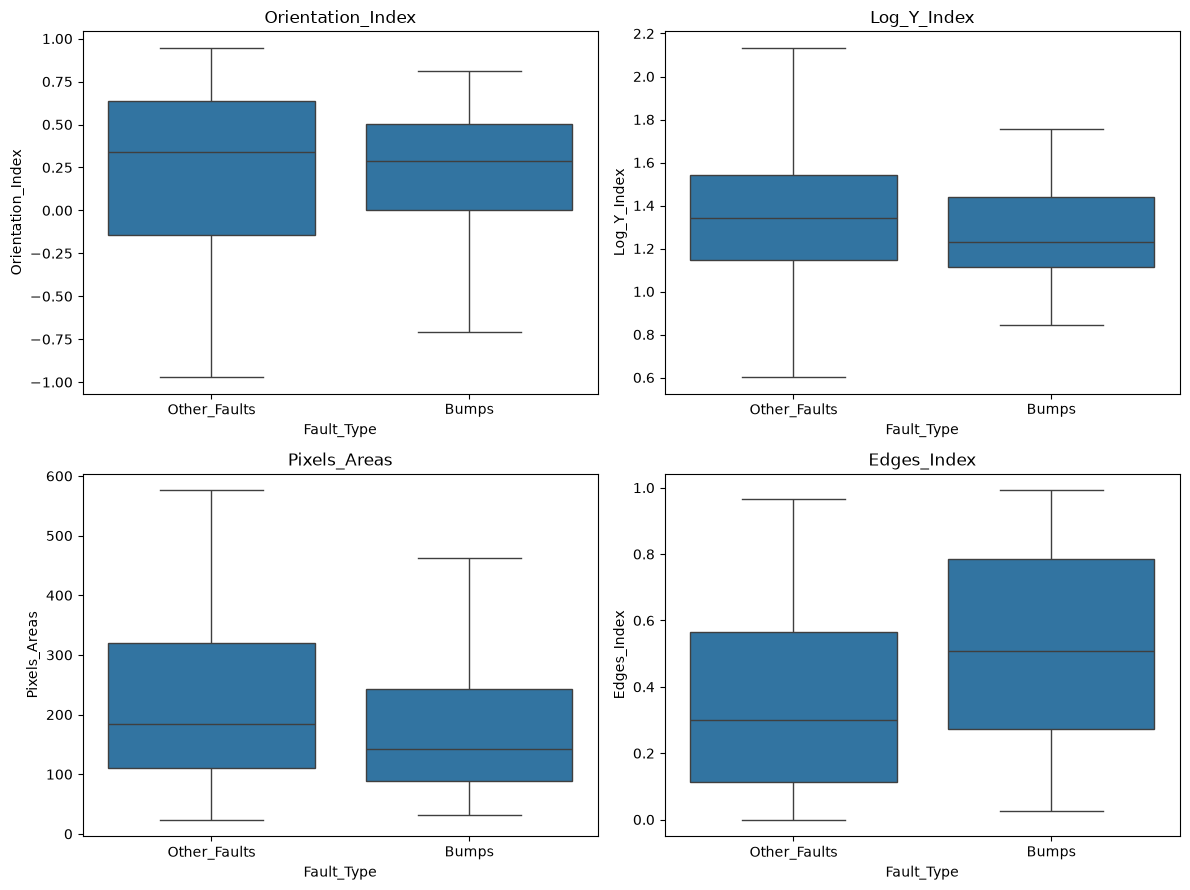

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

labels = np.asarray(CLASSES)

compare = X_base.reset_index(drop=True).copy()
compare["Fault_Type"] = labels[np.asarray(y, dtype=int)]

# A400=1인 Bumps와 Other_Faults만 선택
compare = compare[
    (compare["TypeOfSteel_A400"] == 1) &
    (compare["Fault_Type"].isin([
        "Bumps", "Other_Faults"
    ]))
]

features = [
    "Orientation_Index",
    "Log_Y_Index",
    "Pixels_Areas",
    "Edges_Index"
]

# 실제 유형별 중앙값
display(
    compare.groupby("Fault_Type")[features]
    .median()
    .round(4)
)

# 변수별 박스플롯
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(
        data=compare,
        x="Fault_Type",
        y=feature,
        showfliers=False,
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

## 3. (선택) 개발 데이터 전체로 최종 모델 학습

외부 CV 결과를 먼저 확인하세요. **최종 후보가 선정됐을 때에만** 아래 `RUN_FINAL_FIT=True`로 변경하세요. 하이퍼파라미터 튜닝은 개발 데이터 1,552개만 이용합니다. 기존 Test 데이터는 여기서도 **점수를 계산하지 않습니다**.

여러 차례 기존 Test 결과를 살펴봤기 때문에 그 Test 점수를 새로운 모델의 객관적인 최종 성능이라고 주장하기 어렵습니다. 가능하면 신규 독립 데이터로 평가하세요.

In [19]:
RUN_FINAL_FIT = False  # 최종 후보 확정 후 True로 변경

if RUN_FINAL_FIT:
    final_et_params, final_et_inner = optimize_one('et', X_dev, y_dev, 50, N_TRIALS_ET)
    final_lgb_params, final_lgb_inner = optimize_one('lgb', X_dev, y_dev, 50, N_TRIALS_LGB)
    final_model = make_stack(final_et_params, final_lgb_params)
    final_model.fit(X_dev, y_dev)
    joblib.dump(final_model, 'steel_optuna_stacking.joblib')
    with open('steel_optuna_final_params.json', 'w', encoding='utf-8') as f:
        json.dump({'ExtraTrees': final_et_params, 'LightGBM': final_lgb_params},
                  f, indent=2, ensure_ascii=False)
    print('저장 완료: steel_optuna_stacking.joblib / steel_optuna_final_params.json')
else:
    print('최종 학습 생략. 외부 CV 결과를 먼저 검토하세요.')

최종 학습 생략. 외부 CV 결과를 먼저 검토하세요.


## 해석 가이드

- `Optuna 스태킹` 평균이 기존보다 **실질적으로 높고 Fold마다 일관**되면 후보로 유지
- +0.001처럼 아주 작거나 Fold마다 방향이 뒤집히면 **개선이 확인되지 않은 것**으로 판단
- 0.84는 **목표값**이지 확정적인 달성 수치가 아닙니다. 이전에 나온 강사/수강생 점수와 비교하려면 같은 평가 기준과 같은 분할이 필요합니다.
- 원래 `steel.ipynb`에서 보고된 0.8269는 **다른 CV 설계**이므로 이 노트북의 외부 CV 평균과 숫자만 직접 비교하지 마세요.